# Связная поровая сеть и отсечение от поверхности

**Как пользоваться.** Исполните ячейки по порядку в Colab/Jupyter. Примеры со случайной выборкой проверяют поведение уравнений. Параметры рассеяния, число участков и нормировочная длина — настройки численного опыта. Для интерпретации в физических единицах задайте размеры своего образца и измеренные входы. Маркеры на обзорной 3D-картинке показывают центры.

При полном запуске SEED = None выбирает новый seed. Его значение выводится и сохраняется в parameters.json под именем effective_seed. Чтобы повторить реализацию, введите это целое число в SEED и выполните все ячейки. Сохранённые в архиве примеры и изображения получены при SEED = 42.

## Источник исходных данных

**Базовый эксперимент.** Y. W. Rhee и соавт., *In-Situ Observation of Sintering Shrinkage of UO₂ Compacts Derived from Different Powder Routes*, KNS, 2015, § 2–3, рис. 3. Это та же работа, что использована в расчёте полостей. В ней определяли усадку прессовок разных порошковых маршрутов. Исходные габариты прессовки служат координатной рамкой демонстрации. [Исходная публикация](https://www.kns.org/files/pre_paper/34/15A-419%EC%9D%B4%EC%98%81%EC%9A%B0.pdf).

## 1. Постановка и источник

В представительном кубе узлы соединены горловинами на регулярной решётке. Две противоположные грани сообщаются с газом, боковые грани непроницаемы. Каждая горловина имеет независимый единичный экспоненциальный порог. Рёбра закрываются при накопленной интенсивности A. Связность с внешней средой определяется обходом графа. Сквозная связь и доступность с одной стороны — разные характеристики. Узлы внутри компоненты, утратившей оба выхода, представляют изолированный кластер. Число узлов в нём отличается от числа отдельных кластеров. Морфология открытых пор описана в [работе по UO₂](https://www.sciencedirect.com/science/article/abs/pii/S0022311500000040). Решётка и независимые пороги входят в гипотезу модели.

## 2. Настройки

A — безразмерная накопленная интенсивность закрытия окон. Для перевода в секунды нужен калиброванный закон скорости или измеренная доля сохранившихся горловин. Размеры решётки характеризуют представительный объём, не всю таблетку.

In [1]:
SIDE = 6  # узлов вдоль каждой стороны
EXPOSURES = [0.,0.5,1.,2.,4.]
SEED = None
EDGE_CSV = None  # своя решётка SIDE³: i,j,threshold; нумерация как в np.ndindex
OUTPUT_ROOT = 'uo2_defect_results'

## 3. Исходная сеть

Сохраняем одни и те же пороги для всех стадий. Внешние узлы принадлежат нижней и верхней граням.

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json
from datetime import datetime
from pathlib import Path
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from IPython.display import display,Image
assert type(SIDE) is int and SIDE>=2 and len(EXPOSURES) and all(np.isfinite(EXPOSURES)) and min(EXPOSURES)>=0
out=Path(OUTPUT_ROOT)/'13_connected_network'/datetime.now().strftime('run_%Y%m%d_%H%M%S_%f')
out.mkdir(parents=True)
seed=int(np.random.SeedSequence().entropy) if SEED is None else SEED
print('Seed запуска:', seed)
rng=np.random.default_rng(seed)
xyz=np.array(list(np.ndindex((SIDE,)*3)))
lookup={tuple(point):i for i,point in enumerate(xyz)}
if EDGE_CSV:
    edges=pd.read_csv(EDGE_CSV)
else:
    pairs=[(i,lookup[tuple(p+d)]) for i,p in enumerate(xyz) for d in np.eye(3,dtype=int)
           if tuple(p+d) in lookup]
    edges=pd.DataFrame(pairs,columns=['i','j'])
    edges['threshold']=rng.exponential(size=len(edges))
ij=edges[['i','j']].to_numpy()
assert np.equal(ij,ij.astype(int)).all() and (ij>=0).all() and (ij<len(xyz)).all()
assert np.isfinite(edges.threshold).all() and (edges.threshold>=0).all()
edges.to_csv(out/'edges.csv',index=False)
(out/'parameters.json').write_text(json.dumps(dict(SIDE=SIDE,EXPOSURES=EXPOSURES,effective_seed=seed,seed=seed,EDGE_CSV=EDGE_CSV)))

## 4. Расчёт перехода и пространственная картина

При удалении рёбер число узлов, доступных с поверхности, может только уменьшаться. Красные точки — изолированные узлы. Голубые — доступные хотя бы с одной открытой грани. Серые линии — сохранившиеся горловины.

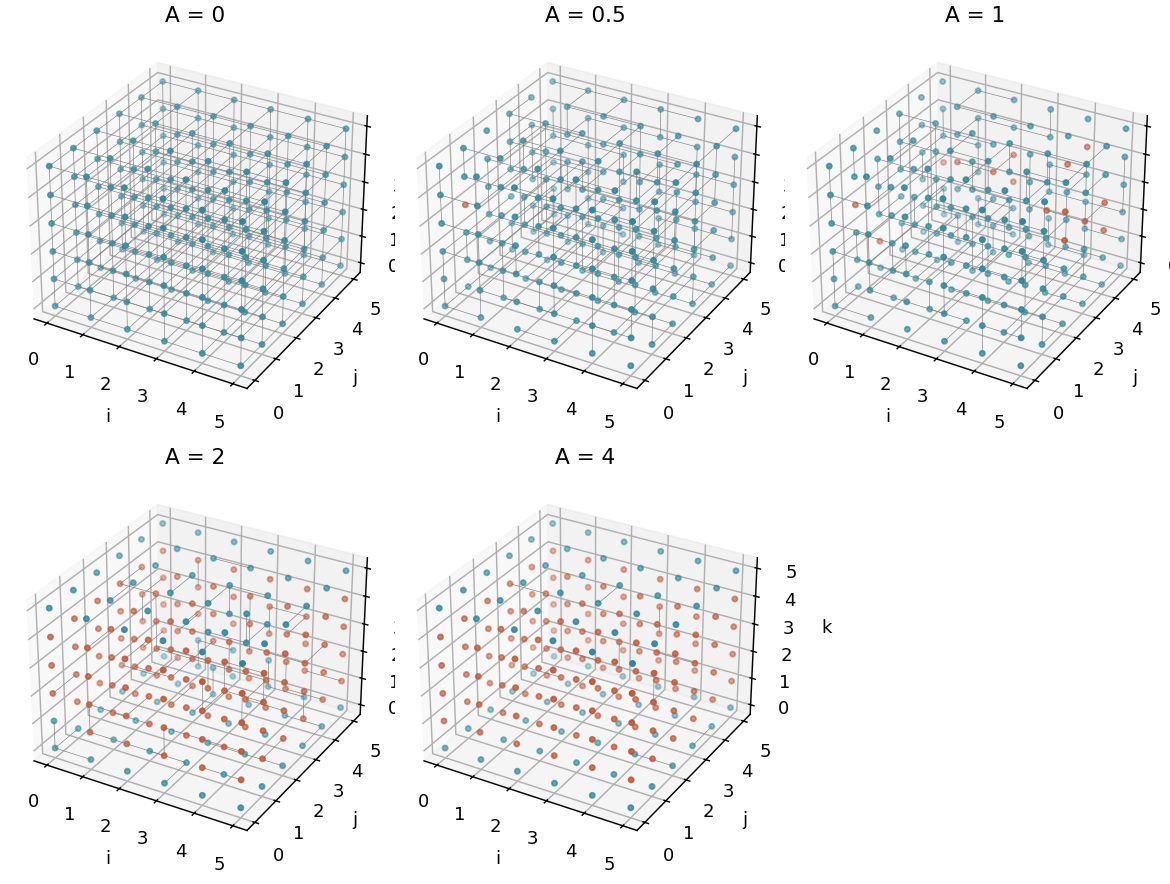

A,open_edges,accessible_nodes,isolated_nodes,isolated_clusters,through
0.0,540,216,0,0,True
0.5,316,215,1,1,True
1.0,208,201,15,11,True
2.0,81,81,135,81,False
4.0,10,72,144,137,False


In [3]:
from mpl_toolkits.mplot3d.art3d import Line3DCollection
rows=[]
fig=plt.figure(figsize=(9,3.4*((len(set(EXPOSURES))+2)//3)),layout='constrained')
last=len(xyz)
for j,A in enumerate(sorted(set(EXPOSURES)),1):
    g=edges.loc[edges.threshold>A]
    graph=coo_matrix((np.ones(len(g)),(g.i,g.j)),shape=(len(xyz),len(xyz)))
    n,labels=connected_components(graph,directed=False)
    bot=set(labels[xyz[:,2]==0]); top=set(labels[xyz[:,2]==SIDE-1])
    access=np.isin(labels,list(bot|top))
    assert access.sum()<=last
    last=access.sum()
    rows.append([A,len(g),last,(~access).sum(),n-len(bot|top),bool(bot&top)])
    df=pd.DataFrame(xyz,columns=['x','y','z']).assign(component=labels,accessible=access)
    df.to_csv(out/f'nodes_{j}.csv',index=False)
    ax=fig.add_subplot((len(set(EXPOSURES))+2)//3,3,j,projection='3d')
    if len(g):
        ax.add_collection3d(Line3DCollection(xyz[g[['i','j']].to_numpy(dtype=int)],colors='gray',linewidths=.35))
    ax.scatter(*xyz.T,c=np.where(access,'#31869a','#bd5637'),s=8)
    ax.set(title=f'A = {A:g}',xlabel='i',ylabel='j',zlabel='k')
fig.savefig(out/'network.png',dpi=130);plt.close(fig);display(Image(filename=str(out/'network.png')))
summary=pd.DataFrame(rows,columns=['A','open_edges','accessible_nodes','isolated_nodes','isolated_clusters','through'])
display(summary);summary.to_csv(out/'summary.csv',index=False)

## 5. Проверка вероятностного закона

Для независимых показательных порогов теоретическая доля сохранившихся горловин равна exp(−A). Доля изолированных узлов дополнительно зависит от топологии.

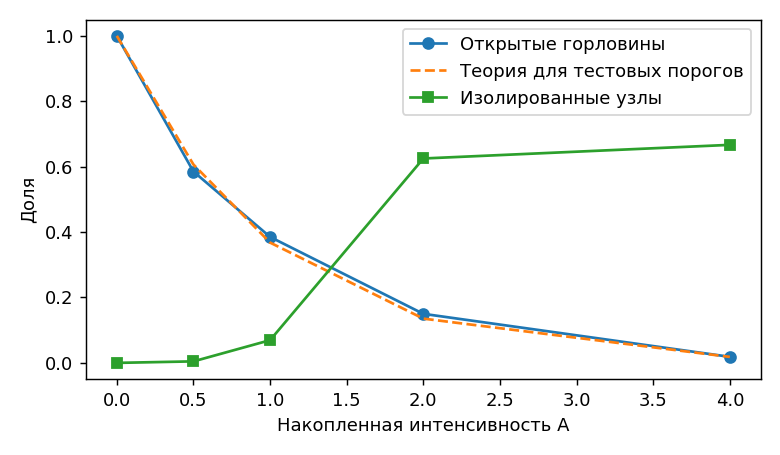

In [4]:
fig,ax=plt.subplots(figsize=(6,3.5))
ax.plot(summary.A,summary.open_edges/max(1,len(edges)),'o-',label='Открытые горловины')
ax.plot(summary.A,np.exp(-summary.A),'--',label='Теория для тестовых порогов')
ax.plot(summary.A,summary.isolated_nodes/len(xyz),'s-',label='Изолированные узлы')
ax.set(xlabel='Накопленная интенсивность A',ylabel='Доля');ax.legend()
fig.tight_layout();fig.savefig(out/'transitions.png',dpi=130);plt.close(fig)
display(Image(filename=str(out/'transitions.png')))